In [ ]:
# Install if needed (uncomment in a fresh environment)
# %pip install -q kagglehub scikit-learn pandas matplotlib

import re
import html
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub

from pathlib import Path
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import FeatureUnion
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42


In [ ]:
# Download the same dataset used in the original notebook.
dataset_path = Path(kagglehub.dataset_download(
    "lakshmi25npathi/imdb-dataset-of-50k-movie-reviews"
))
csv_files = list(dataset_path.rglob("IMDB Dataset.csv"))
if not csv_files:
    raise FileNotFoundError(f"IMDB Dataset.csv was not found under: {dataset_path}")

df = pd.read_csv(csv_files[0])
df = df[["review", "sentiment"]].dropna().drop_duplicates().copy()
df["sentiment"] = df["sentiment"].map({"negative": 0, "positive": 1})
df = df.dropna(subset=["sentiment"])
df["sentiment"] = df["sentiment"].astype(int)

print("Dataset shape:", df.shape)
print(df["sentiment"].value_counts().rename(index={0: "negative", 1: "positive"}))
df.head()


Using Colab cache for faster access to the 'imdb-dataset-of-50k-movie-reviews' dataset.
Dataset shape: (49582, 2)
sentiment
positive    24884
negative    24698
Name: count, dtype: int64


,review,sentiment
0,One of the other reviewers has mentioned that ...,1
1,A wonderful little production. <br /><br />The...,1
2,I thought this was a wonderful way to spend ti...,1
3,Basically there's a family where a little boy ...,0
4,"Petter Mattei's ""Love in the Time of Money"" is...",1


In [ ]:
def clean_review(text):
    text = html.unescape(str(text))
    text = re.sub(r"<[^>]+>", " ", text)                  # HTML tags
    text = re.sub(r"https?://\\S+|www\\.\\S+", " ", text) # URLs
    text = text.lower()
    text = re.sub(r"\\s+", " ", text).strip()
    return text

df["clean_review"] = df["review"].map(clean_review)
df[["review", "clean_review", "sentiment"]].head()


,review,clean_review,sentiment
0,One of the other reviewers has mentioned that ...,one of the other reviewers has mentioned that ...,1
1,A wonderful little production. <br /><br />The...,a wonderful little production. the filming t...,1
2,I thought this was a wonderful way to spend ti...,i thought this was a wonderful way to spend ti...,1
3,Basically there's a family where a little boy ...,basically there's a family where a little boy ...,0
4,"Petter Mattei's ""Love in the Time of Money"" is...","petter mattei's ""love in the time of money"" is...",1


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_review"],
    df["sentiment"],
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=df["sentiment"]
)

print(f"Train size: {len(X_train):,}")
print(f"Test size:  {len(X_test):,}")
print("Train class proportions:")
print(y_train.value_counts(normalize=True).sort_index())


Train size: 37,186
Test size:  12,396
Train class proportions:
sentiment
0    0.498118
1    0.501882
Name: proportion, dtype: float64


In [ ]:
tfidf = FeatureUnion(
    transformer_list=[
        ("word", TfidfVectorizer(
            analyzer="word",
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.98,
            max_features=200_000,
            sublinear_tf=True,
            strip_accents="unicode",
            dtype=np.float32
        )),
        ("char", TfidfVectorizer(
            analyzer="char_wb",
            ngram_range=(3, 5),
            min_df=2,
            max_features=250_000,
            sublinear_tf=True,
            dtype=np.float32
        ))
    ],
    transformer_weights={"word": 1.0, "char": 0.5},
    n_jobs=-1
)

X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)

print("Train feature matrix:", X_train_vec.shape)
print("Test feature matrix: ", X_test_vec.shape)


Train feature matrix: (37186, 450000)
Test feature matrix:  (12396, 450000)


Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best Naive Bayes parameters: {'alpha': 0.03}
Naive Bayes test accuracy: 0.8870
              precision    recall  f1-score   support

    negative     0.8902    0.8819    0.8860      6175
    positive     0.8839    0.8920    0.8879      6221

    accuracy                         0.8870     12396
   macro avg     0.8870    0.8870    0.8870     12396
weighted avg     0.8870    0.8870    0.8870     12396



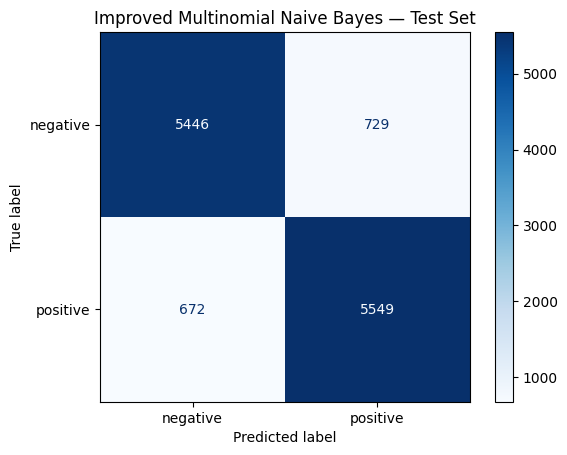

In [ ]:
nb_search = GridSearchCV(
    estimator=MultinomialNB(),
    param_grid={"alpha": [0.03, 0.05, 0.1, 0.2, 0.5, 1.0]},
    scoring="accuracy",
    cv=3,
    n_jobs=-1,
    refit=True,
    verbose=1
)
nb_search.fit(X_train_vec, y_train)

nb_model = nb_search.best_estimator_
pred_nb = nb_model.predict(X_test_vec)

print("Best Naive Bayes parameters:", nb_search.best_params_)
print("Naive Bayes test accuracy:", f"{accuracy_score(y_test, pred_nb):.4f}")
print(classification_report(
    y_test, pred_nb, target_names=["negative", "positive"], digits=4
))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_nb, display_labels=["negative", "positive"], cmap="Blues"
)
plt.title("Improved Multinomial Naive Bayes — Test Set")
plt.show()


Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best Logistic Regression parameters: {'C': 12}
Logistic Regression test accuracy: 0.9186
              precision    recall  f1-score   support

    negative     0.9258    0.9095    0.9176      6175
    positive     0.9117    0.9277    0.9196      6221

    accuracy                         0.9186     12396
   macro avg     0.9188    0.9186    0.9186     12396
weighted avg     0.9187    0.9186    0.9186     12396



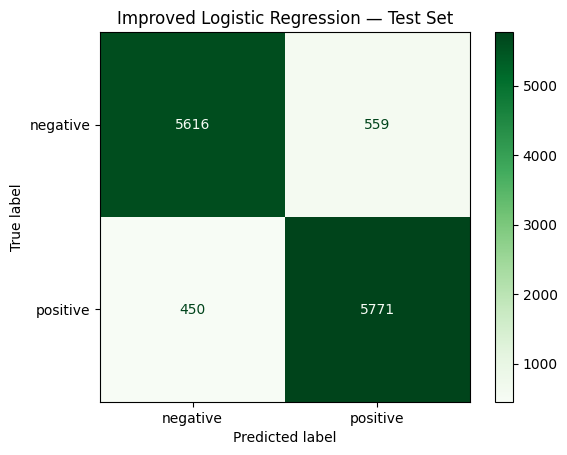

In [ ]:
lr_search = GridSearchCV(
    estimator=LogisticRegression(
        max_iter=2000,
        solver="liblinear",
        random_state=RANDOM_STATE
    ),
    param_grid={"C": [0.5, 1, 2, 4, 8, 12]},
    scoring="accuracy",
    cv=3,
    n_jobs=-1,
    refit=True,
    verbose=1
)
lr_search.fit(X_train_vec, y_train)

lr_model = lr_search.best_estimator_
pred_lr = lr_model.predict(X_test_vec)

print("Best Logistic Regression parameters:", lr_search.best_params_)
print("Logistic Regression test accuracy:", f"{accuracy_score(y_test, pred_lr):.4f}")
print(classification_report(
    y_test, pred_lr, target_names=["negative", "positive"], digits=4
))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_lr, display_labels=["negative", "positive"], cmap="Greens"
)
plt.title("Improved Logistic Regression — Test Set")
plt.show()



,Model,Accuracy
0,Original baseline — Naive Bayes,0.860240
1,Original baseline — Logistic Regression,0.890800
2,Improved — Naive Bayes,0.886980
3,Improved — Logistic Regression,0.918603


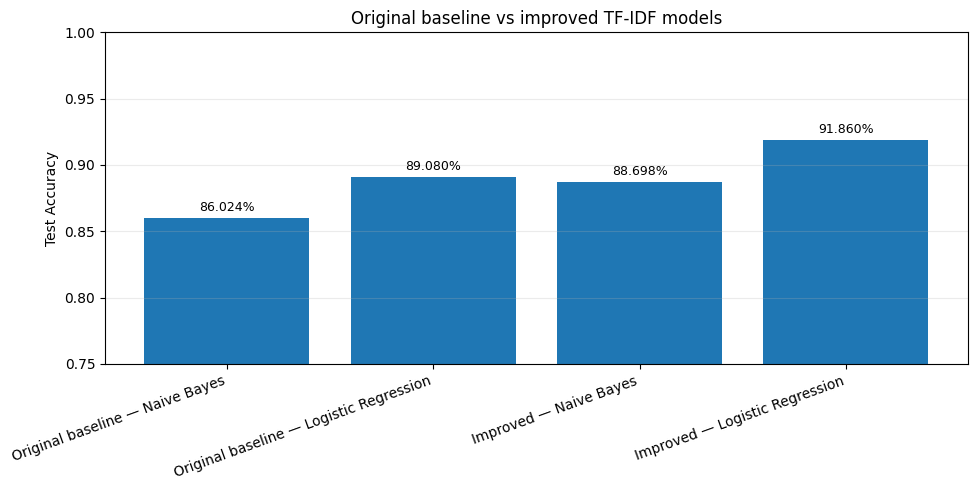

In [ ]:
comparison = pd.DataFrame({
    "Model": ["Original baseline — Naive Bayes", "Original baseline — Logistic Regression",
              "Improved — Naive Bayes", "Improved — Logistic Regression"],
    "Accuracy": [0.86024, 0.8908,
                 accuracy_score(y_test, pred_nb),
                 accuracy_score(y_test, pred_lr)]
})
display(comparison)

plt.figure(figsize=(10, 5))
bars = plt.bar(comparison["Model"], comparison["Accuracy"])
plt.ylim(0.75, 1.0)
plt.ylabel("Test Accuracy")
plt.title("Original baseline vs improved TF-IDF models")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.25)
for bar, score in zip(bars, comparison["Accuracy"]):
    plt.text(bar.get_x() + bar.get_width()/2, score + 0.003, f"{score:.3%}",
             ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()


In [ ]:
test_sentences = [
    "I really loved this movie, it was amazing!",
    "I had high expectations, but this movie was a complete disappointment.",
    "The story was boring and the acting was terrible.",
    "Not bad at all; I actually enjoyed it."
]
clean_sentences = [clean_review(s) for s in test_sentences]
sentence_vec = tfidf.transform(clean_sentences)

nb_preds = nb_model.predict(sentence_vec)
lr_preds = lr_model.predict(sentence_vec)
lr_probs = lr_model.predict_proba(sentence_vec)

for sentence, nb_pred, lr_pred, probs in zip(
    test_sentences, nb_preds, lr_preds, lr_probs
):
    print("Review:", sentence)
    print("Naive Bayes:", "Positive" if nb_pred == 1 else "Negative")
    print("Logistic Regression:", "Positive" if lr_pred == 1 else "Negative",
          f"(P(positive) = {probs[1]:.3f})")
    print("-" * 80)


Review: I really loved this movie, it was amazing!
Naive Bayes: Positive
Logistic Regression: Positive (P(positive) = 1.000)
--------------------------------------------------------------------------------
Review: I had high expectations, but this movie was a complete disappointment.
Naive Bayes: Negative
Logistic Regression: Negative (P(positive) = 0.001)
--------------------------------------------------------------------------------
Review: The story was boring and the acting was terrible.
Naive Bayes: Negative
Logistic Regression: Negative (P(positive) = 0.000)
--------------------------------------------------------------------------------
Review: Not bad at all; I actually enjoyed it.
Naive Bayes: Negative
Logistic Regression: Positive (P(positive) = 0.702)
--------------------------------------------------------------------------------
